# In-Silico CHO Bioreactor Simulation
### Paramaters adopted from Kontoravdi et. al

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

Kinetic paramters for the culturing of CHO cells. Values acquired from Kontoravdi et al.

In [3]:
batchparams = {
    # Cell Growth Kinetics (Eq. 4-6)
    "mu_max": 5.8e-2,       # Max specific growth rate [1/h]
    "K_glc": 7.5e-1,        # Monod constant for glucose [mM]
    "K_gln": 7.5e-2,        # Monod constant for glutamine [mM]
    "KI_lac": 171.76,       # Inhibition constant for lactate [mM]
    "KI_amm": 28.48,        # Inhibition constant for ammonia [mM]

    # Cell Death Kinetics (Eq. 7)
    "mu_d_max": 6.0e-2,     # Max specific death rate [1/h]
    "K_d_amm": 17.6,        # Ammonia constant for cell death [mM], relaxed assumption to model 14-day culture as opposed to 5-day. 
    "n": 2,                 # Death equation power parameter [-]

    # Stoichiometric Yields (Eq. 9, 11, 14, 16)
    "Y_x_glc": 1.1e8,       # Yield of cells on glucose [cell/mmol]
    "Y_x_gln": 5.6e8,       # Yield of cells on glutamine [cell/mmol]
    "Y_lac_glc": 1.4,       # Yield of lactate from glucose [mmol/mmol]
    "Y_amm_gln": 0.43,      # Yield of ammonia from glutamine [mmol/mmol]

    # Maintenance Coefficients (Eq. 9, 12)
    "m_glc": 4.9e-14,       # Glucose maintenance coefficient [mmol/(cell*h)]
    "alpha_1": 3.4e-13,     # Glutamine maintenance constant 1 [mM*L/(cell*h)]
    "alpha_2": 4.0,         # Glutamine maintenance constant 2 [mM]

    # Spontaneous Thermal Degradation (Eq. 10, 15)
    "K_d_gln": 9.6e-3,      # Glutamine degradation constant [1/h]

    # Macroscopic Product Formation (Luedeking-Piret approximation of Eq. 27)
    "alpha_titer": 5.0e-10,   # Growth-associated mAb production [mg/(cell)]
    "beta_titer": 2.5e-9      # Non-growth maintenance mAb production [mg/(cell*h)]
}

Modeling Bioreactor Dynamics through a System of Ordinary Differential Equations

In [5]:
def bioreactorode(t,y,p):
    # define state variables
    viable = max(y[0],0.0)
    glucose = max(y[1],0.0)
    glutamine = max(y[2],0.0)
    lactate = max(y[3],0.0)
    ammonia = max(y[4],0.0)
    titer = max(y[5],0.0)
    volume = y[6] 

    # Day 5 Temperature Shift Rates
    mu_max_eff = p["mu_max"] * (0.60 if t >= 120 else 1.0)
    beta_titer_eff = p["beta_titer"] * (1.75 if t >= 120 else 1.0)
    
    #define eq for cell growth rate
    if glucose > 0.01 and glutamine > 0.01:
        f_lim = (glucose/(p["K_glc"]+glucose))*(glutamine/(p["K_gln"]+glutamine))
        f_inh = (p["KI_lac"]/(p["KI_lac"]+lactate))*(p["KI_amm"]/(p["KI_amm"]+ammonia))
        mu = mu_max_eff*f_lim*f_inh
    else:
        mu = 0.0
        
    #define eq for cell death rate
    mu_d = p["mu_d_max"]/(1.0+(p["K_d_amm"]/(ammonia+1e-6))**p["n"])

    # Metabolic uptake rates
    m_gln = (p["alpha_1"]*glutamine)/(p["alpha_2"]+glutamine)
    Q_glc = (mu/p["Y_x_glc"])+p["m_glc"]
    Q_gln = (mu/p["Y_x_gln"])+m_gln

    # Byproduct synthesis rates
    Q_lac = Q_glc*p["Y_lac_glc"]
    Q_amm = Q_gln*p["Y_amm_gln"]
    q_p = (mu*p["alpha_titer"])+beta_titer_eff

    # Feeding Process (Activates when glucose levels deplete after day 3
    F_in = 0.004 if (p.get("feed_on", True))and(t >=48 and volume < 2.0) else 0.0 #L/h
    feed_glc = 150.0 #mM
    feed_gln = 15.0 #mM
    dilution = F_in/volume # 1/h

    # Mass balances accounting for dilution
    dviable_dt = (mu-mu_d)*viable-(dilution*viable)
    dglucose_dt = -Q_glc*viable+dilution*(feed_glc-glucose)
    dglutamine_dt = -Q_gln*viable-p["K_d_gln"]*glutamine+dilution*(feed_gln-glutamine)
    dlactate_dt = Q_lac*viable-(dilution*lactate)
    dammonia_dt = Q_amm*viable-(dilution*ammonia)
    dtiter_dt = q_p*viable-(dilution*titer)
    dvolume_dt = F_in

    return [dviable_dt,dglucose_dt,dglutamine_dt,dlactate_dt,dammonia_dt,dtiter_dt,dvolume_dt]

Set initial conditions and solve the mass balance equations. 

In [7]:
# Conditions at day 0
y0 = [1.0e8,40.0,5.0,0.0,0.0,0.0,1.0]
t_span = (0,336) #14 day span 
t_eval = np.linspace(0,336,1000)

fedsol = solve_ivp(bioreactorode,t_span,y0,args=(batchparams,),t_eval=t_eval,method="RK45")
unfedsol = solve_ivp(bioreactorode,t_span,y0,args=({**batchparams,"feed_on": False},),t_eval=t_eval,method="RK45")

Generated Outputs

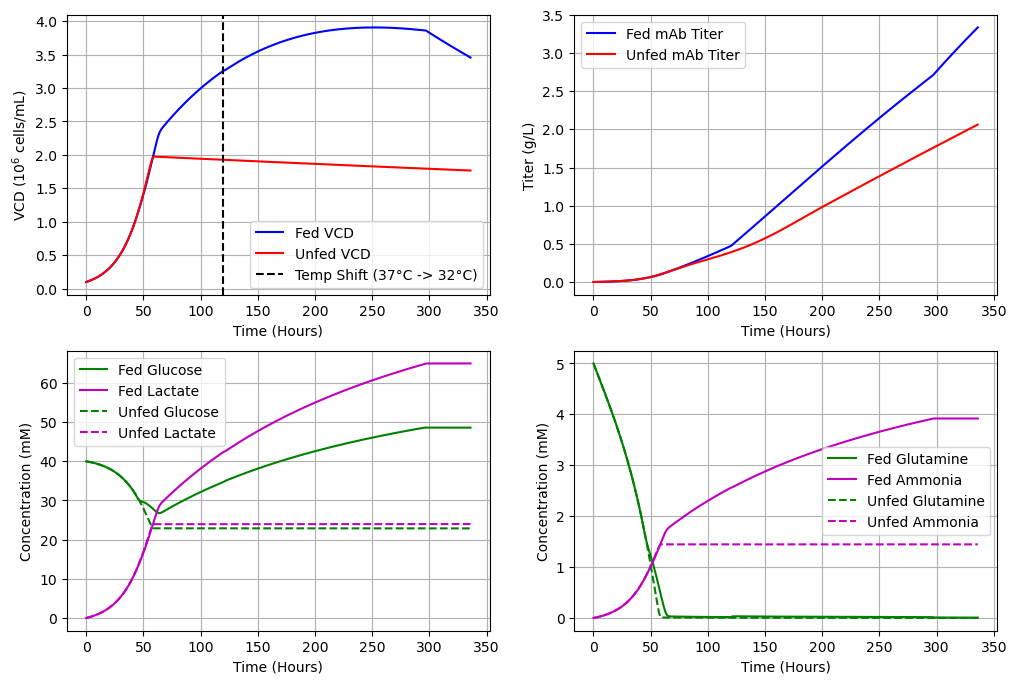

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

axs[0,0].plot(fedsol.t,fedsol.y[0]/1e9,"b-",label="Fed VCD")
axs[0,0].plot(unfedsol.t,unfedsol.y[0]/1e9,"r-",label="Unfed VCD")
axs[0,0].set_xlabel("Time (Hours)")
axs[0,0].set_ylabel("VCD ($10^6$ cells/mL)")
axs[0,0].axvline(x=120, color="black", linestyle="--", label="Temp Shift (37°C -> 32°C)")
axs[0,0].legend()
axs[0,0].grid(True)

axs[0,1].plot(fedsol.t,fedsol.y[5]/1000,"b-",label="Fed mAb Titer")
axs[0,1].plot(unfedsol.t,unfedsol.y[5]/1000,"r-",label="Unfed mAb Titer")
axs[0,1].set_xlabel("Time (Hours)")
axs[0,1].set_ylabel("Titer (g/L)")
axs[0,1].legend()
axs[0,1].grid(True)

axs[1,0].plot(fedsol.t,fedsol.y[1],"g-",label="Fed Glucose")
axs[1,0].plot(fedsol.t,fedsol.y[3],"m-",label="Fed Lactate")
axs[1,0].plot(unfedsol.t,unfedsol.y[1],"g--",label="Unfed Glucose")
axs[1,0].plot(unfedsol.t,unfedsol.y[3],"m--",label="Unfed Lactate")
axs[1,0].set_xlabel("Time (Hours)")
axs[1,0].set_ylabel("Concentration (mM)")
axs[1,0].legend()
axs[1,0].grid(True)

axs[1,1].plot(fedsol.t,fedsol.y[2],"g-",label="Fed Glutamine")
axs[1,1].plot(fedsol.t,fedsol.y[4],"m-",label="Fed Ammonia")
axs[1,1].plot(unfedsol.t,unfedsol.y[2],"g--",label="Unfed Glutamine")
axs[1,1].plot(unfedsol.t,unfedsol.y[4],"m--",label="Unfed Ammonia")
axs[1,1].set_xlabel("Time (Hours)")
axs[1,1].set_ylabel("Concentration (mM)")
axs[1,1].legend()
axs[1,1].grid(True)

plt.show()